TensorFlow Version: 2.21.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 899s 5us/step
Selected Image: Automobile
Image Shape: (32, 32, 3)


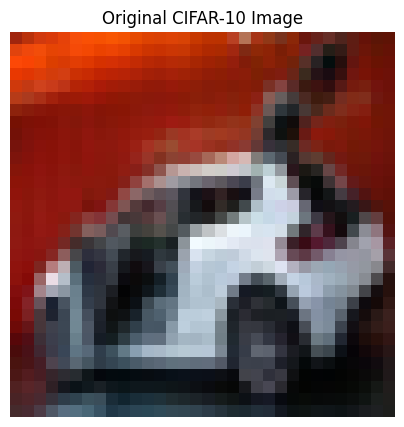


Filter: Horizontal Edge
Stage A Shape: (32, 32)
Stage B Shape: (32, 32)
Stage C Shape: (16, 16)
Stage D Shape: (16, 16)

Filter: Vertical Edge
Stage A Shape: (32, 32)
Stage B Shape: (32, 32)
Stage C Shape: (16, 16)
Stage D Shape: (16, 16)

Filter: Sharpen
Stage A Shape: (32, 32)
Stage B Shape: (32, 32)
Stage C Shape: (16, 16)
Stage D Shape: (16, 16)

Filter: Gaussian Blur
Stage A Shape: (32, 32)
Stage B Shape: (32, 32)
Stage C Shape: (16, 16)
Stage D Shape: (16, 16)

Filter: Emboss
Stage A Shape: (32, 32)
Stage B Shape: (32, 32)
Stage C Shape: (16, 16)
Stage D Shape: (16, 16)


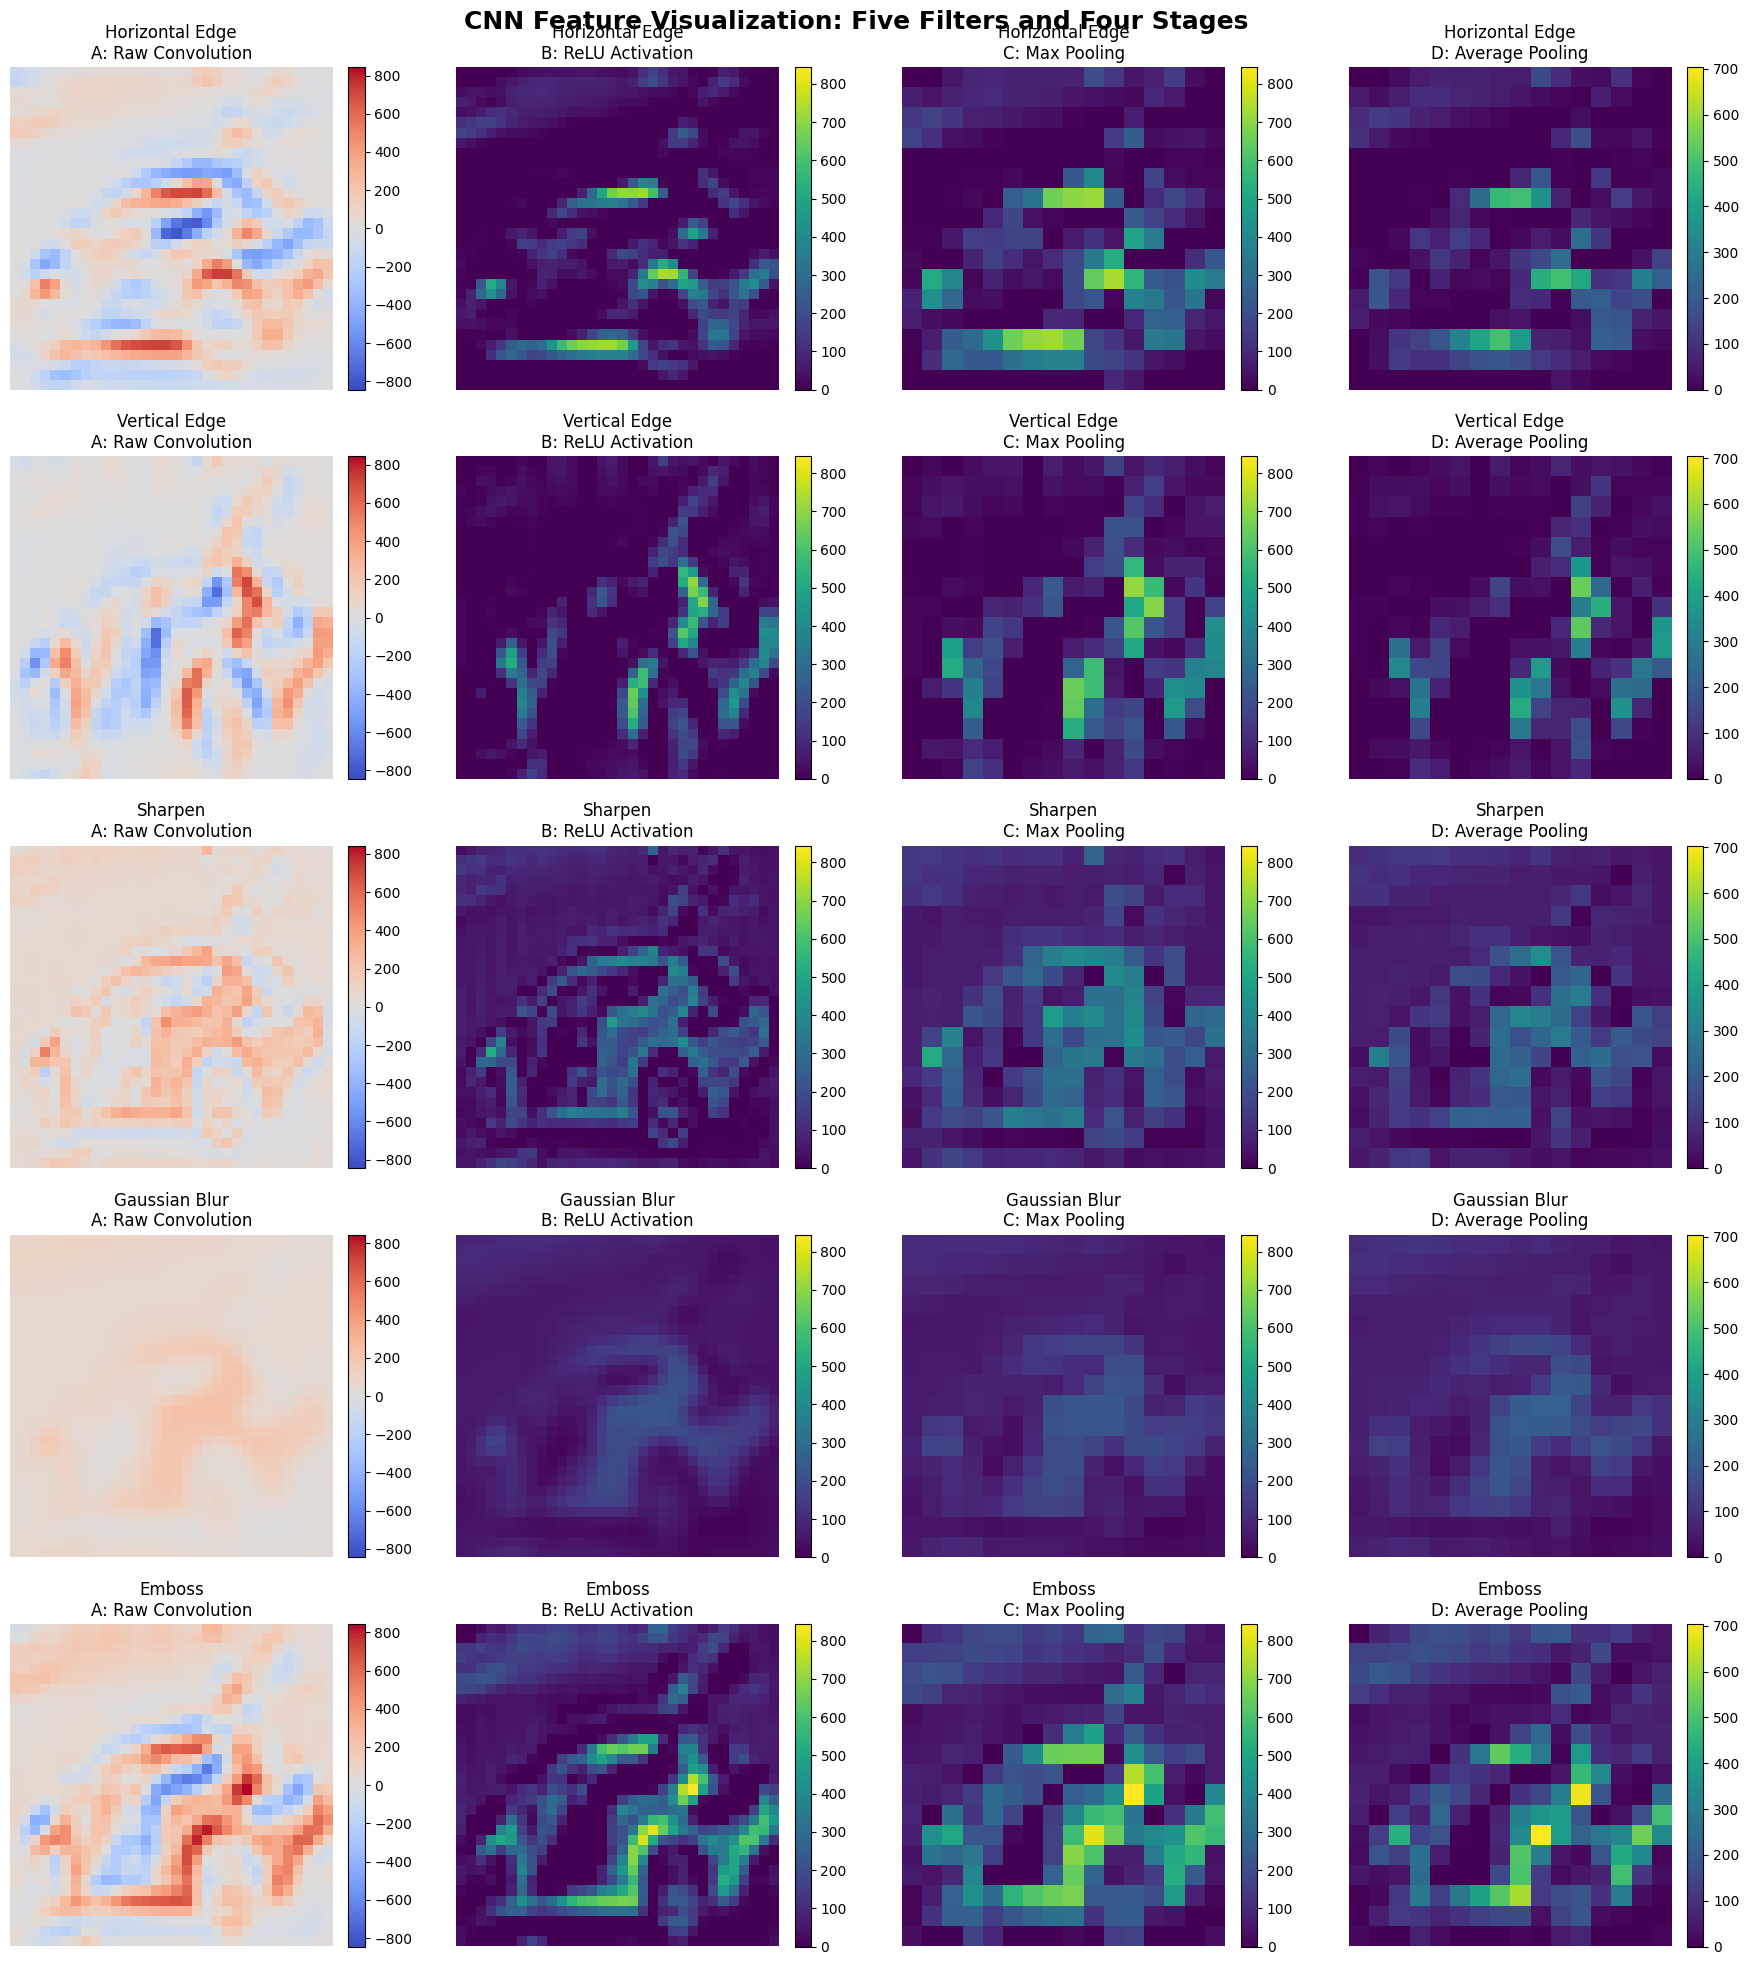


5 x 4 Visualization Grid Generated Successfully!

========== MANUAL PARAMETER AUDIT ==========

MODEL A: STANDARD 3x3
Conv1 Parameters: 140
Conv2 Parameters: 460
Dense Parameters: 110
Total Parameters: 710

MODEL B: LARGE 5x5
Conv1 Parameters: 380
Conv2 Parameters: 1260
Dense Parameters: 110
Total Parameters: 1750

Percentage Increase: 146.47887323943664 %

========== MODEL A SUMMARY ==========


Model: "Model_A_Standard"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)


 FINAL MODEL COMPARISON 
Model A Manual Parameters: 710
Model A Framework Parameters: 710
Model B Manual Parameters: 1750
Model B Framework Parameters: 1750

Parameter Increase: 146.48 %

Assignment Implementation Completed Successfully!


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from scipy.signal import convolve2d
from tensorflow.keras import layers, models

print("TensorFlow Version:", tf.__version__)

print("\nDownloading CIFAR-10 Dataset...")

(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

# Select an automobile or truck image
selected_index = np.where(
    (y_test.flatten() == 1) | (y_test.flatten() == 9)
)[0][0]

input_image = x_test[selected_index]

print("Selected Image:", class_names[y_test[selected_index][0]])
print("Image Shape:", input_image.shape)

# Display original RGB image
plt.figure(figsize=(5, 5))
plt.imshow(input_image)
plt.title("Original CIFAR-10 Image")
plt.axis("off")
plt.show()

# Convert RGB image into grayscale
gray_image = np.mean(input_image.astype(np.float32), axis=2)

kernels = {

    "Horizontal Edge": np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ], dtype=np.float32),

    "Vertical Edge": np.array([
        [-1,  0,  1],
        [-2,  0,  2],
        [-1,  0,  1]
    ], dtype=np.float32),

    "Sharpen": np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ], dtype=np.float32),

    "Gaussian Blur": np.array([
        [1, 2, 1],
        [2, 4, 2],
        [1, 2, 1]
    ], dtype=np.float32) / 16,

    "Emboss": np.array([
        [-2, -1,  0],
        [-1,  1,  1],
        [ 0,  1,  2]
    ], dtype=np.float32)
}

def max_pooling(image):
    h, w = image.shape

    image = image[:h - h % 2, :w - w % 2]

    return image.reshape(
        image.shape[0] // 2, 2,
        image.shape[1] // 2, 2
    ).max(axis=(1, 3))


def average_pooling(image):
    h, w = image.shape

    image = image[:h - h % 2, :w - w % 2]

    return image.reshape(
        image.shape[0] // 2, 2,
        image.shape[1] // 2, 2
    ).mean(axis=(1, 3))


# Store all intermediate feature maps
results = {}

for filter_name, kernel in kernels.items():

    # Stage A: Raw Convolution
    raw_output = convolve2d(
        gray_image,
        kernel,
        mode='same',
        boundary='symm'
    )

    # Stage B: ReLU Activation
    relu_output = np.maximum(0, raw_output)

    # Stage C: Max Pooling
    max_output = max_pooling(relu_output)

    # Stage D: Average Pooling
    avg_output = average_pooling(relu_output)

    results[filter_name] = [
        raw_output,
        relu_output,
        max_output,
        avg_output
    ]

    print("\nFilter:", filter_name)
    print("Stage A Shape:", raw_output.shape)
    print("Stage B Shape:", relu_output.shape)
    print("Stage C Shape:", max_output.shape)
    print("Stage D Shape:", avg_output.shape)

fig, axes = plt.subplots(
    5, 4,
    figsize=(18, 20)
)

stage_names = [
    "A: Raw Convolution",
    "B: ReLU Activation",
    "C: Max Pooling",
    "D: Average Pooling"
]

# Shared intensity scales for comparable feature maps
raw_limit = max(
    np.max(np.abs(result[0]))
    for result in results.values()
)

relu_limit = max(
    np.max(result[1])
    for result in results.values()
)

max_limit = max(
    np.max(result[2])
    for result in results.values()
)

avg_limit = max(
    np.max(result[3])
    for result in results.values()
)

limits = [
    (-raw_limit, raw_limit),
    (0, relu_limit),
    (0, max_limit),
    (0, avg_limit)
]

for row, (filter_name, feature_maps) in enumerate(results.items()):

    for col, feature_map in enumerate(feature_maps):

        vmin, vmax = limits[col]

        if col == 0:
            cmap = 'coolwarm'
        else:
            cmap = 'viridis'

        im = axes[row, col].imshow(
            feature_map,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax
        )

        axes[row, col].set_title(
            f"{filter_name}\n{stage_names[col]}"
        )

        axes[row, col].axis('off')

        fig.colorbar(
            im,
            ax=axes[row, col],
            fraction=0.046,
            pad=0.04
        )

plt.suptitle(
    "CNN Feature Visualization: Five Filters and Four Stages",
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig(
    "CNN_Feature_Visualization.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("\n5 x 4 Visualization Grid Generated Successfully!")


# ============================================================
# PART 5: MANUAL PARAMETER CALCULATION
# ============================================================

def conv_parameters(kernel_size, input_channels, output_channels):

    return (
        kernel_size * kernel_size * input_channels + 1
    ) * output_channels


def calculate_model_parameters(kernel_size):

    conv1 = conv_parameters(
        kernel_size, 3, 5
    )

    conv2 = conv_parameters(
        kernel_size, 5, 10
    )

    # Global Average Pooling produces 10 values
    # Dense layer: 10 inputs and 10 outputs
    dense = (10 * 10) + 10

    total = conv1 + conv2 + dense

    return conv1, conv2, dense, total


# Model A: 3x3 kernels
a1, a2, ad, total_a = calculate_model_parameters(3)

# Model B: 5x5 kernels
b1, b2, bd, total_b = calculate_model_parameters(5)

print("\n========== MANUAL PARAMETER AUDIT ==========")

print("\nMODEL A: STANDARD 3x3")
print("Conv1 Parameters:", a1)
print("Conv2 Parameters:", a2)
print("Dense Parameters:", ad)
print("Total Parameters:", total_a)

print("\nMODEL B: LARGE 5x5")
print("Conv1 Parameters:", b1)
print("Conv2 Parameters:", b2)
print("Dense Parameters:", bd)
print("Total Parameters:", total_b)

percentage_increase = (
    (total_b - total_a) / total_a
) * 100

print("\nPercentage Increase:", percentage_increase, "%")


# ============================================================
# PART 6: BUILD MODEL A (STANDARD CNN)
# ============================================================

model_a = models.Sequential([

    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(
        5,
        kernel_size=(3, 3),
        activation='relu',
        padding='same'
    ),

    layers.Conv2D(
        10,
        kernel_size=(3, 3),
        activation='relu',
        padding='same'
    ),

    layers.MaxPooling2D(
        pool_size=(2, 2),
        strides=2
    ),

    layers.GlobalAveragePooling2D(),

    layers.Dense(10, activation='softmax')

], name="Model_A_Standard")

print("\n========== MODEL A SUMMARY ==========")
model_a.summary()

assert model_a.count_params() == total_a

model_b = models.Sequential([

    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(
        5,
        kernel_size=(5, 5),
        activation='relu',
        padding='same'
    ),

    layers.Conv2D(
        10,
        kernel_size=(5, 5),
        activation='relu',
        padding='same'
    ),

    layers.AveragePooling2D(
        pool_size=(2, 2),
        strides=2
    ),

    layers.GlobalAveragePooling2D(),

    layers.Dense(10, activation='softmax')

], name="Model_B_Large_Kernel")

print("\n MODEL B SUMMARY ")
model_b.summary()

assert model_b.count_params() == total_b

print("\n FINAL MODEL COMPARISON " )

print("Model A Manual Parameters:", total_a)
print("Model A Framework Parameters:", model_a.count_params())

print("Model B Manual Parameters:", total_b)
print("Model B Framework Parameters:", model_b.count_params())

print(
    "\nParameter Increase:",
    round(percentage_increase, 2),
    "%"
)

print("\nAssignment Implementation Completed Successfully!")

